# Від сегментів покупців до рекомендацій книг · пари 35–36

**240 хв навчання:** повторення пар 33–34 — 40 хв; content-based (35) — 100 хв; collaborative filtering (36) — 100 хв. Перерви та встановлення середовища поза цим часом.

Ви допомагаєте книжковому магазину. Спершу згадаєте, чим групування покупців відрізняється від поради конкретної книги. Потім побудуєте рекомендації за авторами й описами, а далі — за спільними оцінками читачів. Результат: відтворюваний аналіз і book_recommendations.csv.

**Ритм:** пояснення → запущений приклад → коротке самостійне завдання → покрокові підказки → перевірка. Завдання мають номери 1–10 у всіх форматах.

## Як відкрити

У корені python61_ai активуйте спільне .venv. Для ноутбука запустіть `python -m jupyterlab` і виберіть PythonAI_Author_Lesson35_Lesson36.ipynb. Виконуйте комірки згори вниз. У комірках завдань залишене місце для власного коду; наступні демонстрації не залежать від правильності ваших відповідей.

Папка PythonAI_Author_Lesson35_Lesson36 містить examples, tasks, data і власний requirements.txt. Кожен .py запускається окремо, без попереднього прикладу; у tasks є умови та підказки. Один зі способів запуску з кореня:

```bash
python PythonAI_Author_Lesson35_Lesson36/examples/example_01.py
python PythonAI_Author_Lesson35_Lesson36/tasks/task_01.py
```

Нових бібліотек до спільного requirements не потрібно: використовуємо numpy, pandas, matplotlib і scikit-learn. Для окремого середовища встановіть requirements.txt саме папки пари. Ноутбук самодостатній, початкова комірка містить локальні навчальні дані. У HTML код показаний для копіювання в Python; браузер його не виконує.

**Про дані.** 12 записів каталогу, 6 вигаданих читачів, оцінки 1..5. Назви книг використано для впізнаваності; короткі описи та рейтинги створено для навчання. Це не Goodreads і не вимірювання реальних читацьких смаків. Книга b12 — навчальний запис без рейтингів. CSV лежать у data для огляду; однакові таблиці також задані кодом у workshop.py, щоб запуск не залежав від мережі або поточного каталогу.

**Межа часу.** Train містить лише події до 2026-02-01, test — після. У прикладах ніколи не навчаємо рекомендації на майбутніх оцінках. Seed=42 фіксує повторення кластеризації.

| Хв від початку | Блок | Завдання |
|---|---|---|
| 0–20 | 33 · сегменти й нова задача | 1 |
| 20–40 | 34 · щільність і місток | 2 |
| 40–65 | 35.1 · каталог і TF-IDF | 3 |
| 65–90 | 35.2 · cosine | 4 |
| 90–115 | 35.3 · top-n | 5 |
| 115–140 | 35.4 · інтерес читача | 6 |
| 140–165 | 36.1 · user-item | 7 |
| 165–190 | 36.2 · зважений прогноз | 8 |
| 190–215 | 36.3 · unseen, fallback, CSV | 9 |
| 215–240 | 36.4 · часовий поділ і перевірка | 10 |

## Підготовка — запустіть один раз


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Навчальний каталог: назви відомі, короткі описи написано для цієї вправи.
# Англійські ключові слова дозволяють зосередитися на TF-IDF, без лематизації.
books = pd.DataFrame([
    ('b01', 'Гобіт', 'Tolkien', 'fantasy dragon journey friendship'),
    ('b02', 'Володар перснів', 'Tolkien', 'fantasy ring journey friendship'),
    ('b03', 'Гаррі Поттер і філософський камінь', 'Rowling', 'fantasy magic school friendship'),
    ('b04', 'Гаррі Поттер і таємна кімната', 'Rowling', 'fantasy magic school mystery'),
    ('b05', 'Чарівник Земномор’я', 'LeGuin', 'fantasy wizard island journey'),
    ('b06', 'Гробниці Атуану', 'LeGuin', 'fantasy island tomb journey'),
    ('b07', 'Фундація', 'Asimov', 'science space empire future'),
    ('b08', 'Я, робот', 'Asimov', 'science robot future ethics'),
    ('b09', 'Убивство у Східному експресі', 'Christie', 'detective train crime mystery'),
    ('b10', 'Смерть на Нілі', 'Christie', 'detective river crime mystery'),
    ('b11', 'Прикладне машинне навчання', 'Geron', 'python machine learning models'),
    ('b12', 'Навчальний довідник моделей', 'Workshop', 'python machine learning practice'),
], columns=['book_id', 'title', 'authors', 'description'])

# Вигадані оцінки 1..5. Відсутній рядок — невідома оцінка, не нуль зірок.
history = {
    'Olia': [('b01',5),('b03',4),('b09',1),('b05',4)],
    'Ira': [('b01',5),('b03',4),('b09',1),('b02',5),('b04',4),('b06',3)],
    'Max': [('b01',1),('b03',1),('b09',4),('b07',5),('b08',5),('b10',5)],
    'Taras': [('b01',4),('b03',5),('b09',2),('b02',4),('b04',5),('b05',4)],
    'Nadia': [('b01',2),('b03',2),('b09',3),('b02',2),('b05',5),('b06',5)],
    'Lena': [('b01',5),('b03',4),('b09',1),('b04',4),('b05',3)],
}
rows = []
for user_no, (user, items) in enumerate(history.items()):
    for day, (book, rating) in enumerate(items):
        timestamp = pd.Timestamp('2026-01-01') + pd.Timedelta(days=day*4+user_no)
        rows.append((user, book, rating, timestamp))
# Майбутні оцінки після спільного cutoff; модель до них доступу не матиме.
for offset, (user, book, rating) in enumerate([
    ('Olia','b02',5), ('Ira','b05',4), ('Max','b02',1),
    ('Taras','b06',4), ('Nadia','b04',2), ('Lena','b02',5),
]):
    rows.append((user,book,rating,pd.Timestamp('2026-03-01')+pd.Timedelta(days=offset)))
events = pd.DataFrame(rows, columns=['user_id','book_id','rating','timestamp'])
events = events.sort_values(['timestamp','user_id','book_id']).reset_index(drop=True)
cutoff = pd.Timestamp('2026-02-01')
train = events.loc[events.timestamp < cutoff].copy()
test = events.loc[events.timestamp >= cutoff].copy()

assert books.book_id.is_unique
assert not events.duplicated(['user_id','book_id']).any()
assert events.rating.between(1,5).all()
assert set(events.book_id) <= set(books.book_id)
assert train.timestamp.max() < test.timestamp.min()


def customer_data():
    """Дві фізично зрозумілі ознаки й один нетиповий клієнт; seed фіксовано."""
    rng = np.random.default_rng(42)
    groups = [rng.normal(c,[50,0.6],size=(25,2))
              for c in ([350,2],[1800,12],[900,6])]
    return np.vstack(groups + [np.array([[5000,1]])])


OUTPUT_DIR = Path.cwd() / 'results_35_36'


# Блок 1. 33 · Від сегмента покупців до особистої рекомендації

**0–20 хв.**

## Що вже вміє наш магазин

На попередній зустрічі ми знаходили групи схожих покупців. Сьогодні магазин ставить точніше питання: «Яку книжку показати Олі наступною?» Група допомагає описати людей, але ще не визначає конкретну книжку для конкретної людини.

**Факт 1. Кластеризація повертає групу об'єкта, а рекомендація — впорядкований список інших об'єктів для нього.**

Схема: витрати й замовлення → масштабування → K-Means → сегмент → нове питання про книжку.

У повторенні маємо 76 синтетичних покупців, дві ознаки: середній чек і кількість замовлень за місяць. K-Means призначає кожному найближчий центр і пересуває центр у середнє своєї групи. k=3 — наше рішення. Номер групи не є рейтингом людини.

Гривні чисельно більші за кількість замовлень, тому спершу StandardScaler. Для нового покупця застосовуємо той самий transform і predict, а не fit на одному рядку. Навіть віддалений покупець отримає найближчий центр. Ця межа підводить до DBSCAN у наступному блоці.

У самих двох ознаках немає інформації про книжкові вподобання. Не можна чесно вивести «любить фентезі» з великого чека. Для рекомендацій знадобиться інший сигнал: зміст книжок або історія оцінок.

In [2]:
customers = customer_data()
customer_scaler = StandardScaler().fit(customers)
customers_scaled = customer_scaler.transform(customers)
customer_km = KMeans(n_clusters=3,n_init=10,random_state=42).fit(customers_scaled)

### Приклад: основний код

In [3]:
print('Розміри сегментів:',pd.Series(customer_km.labels_).value_counts().sort_index().to_dict())

Розміри сегментів: {0: 26, 1: 25, 2: 25}


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

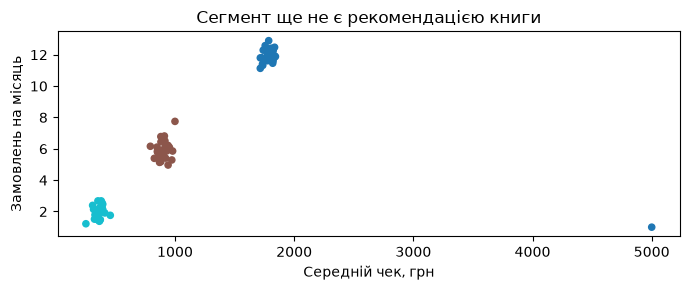

In [4]:
fig, ax = plt.subplots(figsize=(7,3))
ax.scatter(customers[:,0],customers[:,1],c=customer_km.labels_,cmap='tab10',s=20)
ax.set(xlabel='Середній чек, грн',ylabel='Замовлень на місяць',title='Сегмент ще не є рекомендацією книги')
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 1. Новий покупець.** Для рядка [850, 6] знайдіть сегмент та відстань до найближчого центру. Порівняйте із [5000, 1]. Скажіть, чи доводять ці два числа, яку книжку покупець хоче прочитати.

### Підказки

1. Створіть масив двох рядків через np.array.
2. Перетворіть його customer_scaler.transform; не навчайте новий scaler.
3. customer_km.predict дасть дві мітки, customer_km.transform — відстані до трьох центрів.
4. Для мінімуму в кожному рядку використайте `.min(axis=1)`.
5. Висновок має назвати, якої інформації про інтереси нам бракує.

**Готово, якщо:** Є два призначення, дві відстані й пояснення різниці між сегментом та особистою рекомендацією.

In [ ]:
# Завдання 1: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 2. 34 · DBSCAN: нетипова точка та межа старої задачі

**20–40 хв.**

## Кого можна залишити поза групами

**Факт 2. DBSCAN може позначити рідкісне оточення як шум, але не пояснює читацький смак.**

Схема: радіус eps → сусіди → ядра й межові → групи або -1 → перевірка змісту ознак.

Ядрова точка має в радіусі eps принаймні min_samples точок, включно із собою у scikit-learn. Межова має замало власних сусідів, але лежить біля ядра. Інші точки можуть отримати -1. Це шум за поточними параметрами, а не шахрайство чи помилка даних.

На тих самих масштабованих покупцях DBSCAN не отримує кількість груп наперед. Ми задаємо щільність через eps і min_samples. Малий радіус може розсипати хмари, великий — склеїти. Номери кластерів двох алгоритмів не слід порівнювати як однакові назви.

Тепер змінимо саму задачу. Пара 35 відповідає «Яка книга схожа за змістом на цю?», навіть без рейтингів. Пара 36 — «Що оцінили люди зі схожою історією?» Один метод порівнює ознаки речей, інший використовує спільні реакції людей. Жоден із них не вгадує вподобання з самого номера сегмента.

In [6]:
customers = customer_data()
customers_scaled = StandardScaler().fit_transform(customers)
customer_db = DBSCAN(eps=0.35,min_samples=4).fit(customers_scaled)

### Приклад: основний код

In [7]:
print('Груп:',len(set(customer_db.labels_) - {-1}))
print('Шум:',int((customer_db.labels_ == -1).sum()))
print('Чи є predict:',hasattr(customer_db,'predict'))

Груп: 3
Шум: 1
Чи є predict: False


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

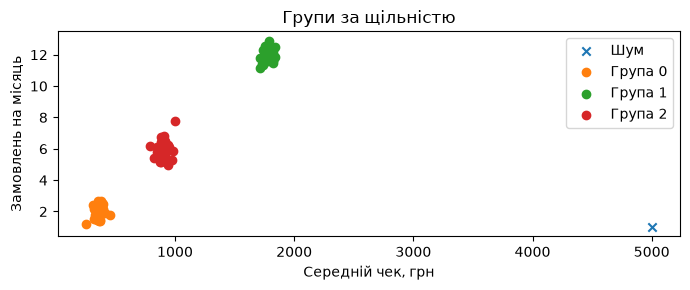

In [8]:
fig, ax = plt.subplots(figsize=(7,3))
for label in sorted(set(customer_db.labels_)):
    mask = customer_db.labels_ == label
    ax.scatter(customers[mask,0],customers[mask,1],marker='x' if label == -1 else 'o',
               label='Шум' if label == -1 else f'Група {label}')
ax.set(xlabel='Середній чек, грн',ylabel='Замовлень на місяць',title='Групи за щільністю')
ax.legend()
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 2. Перевірте радіус.** Для eps=0.15 і eps=3.0 надрукуйте кількість кластерів та шуму. Закінчіть дві фрази: «Для content-based потрібні…», «Для collaborative потрібні…».

### Підказки

1. Зберігайте customers_scaled і min_samples=4 незмінними.
2. Зробіть цикл за двома радіусами й викличте fit_predict.
3. Кластери рахуйте без -1: `len(set(labels) - {-1})`.
4. Шум: `(labels == -1).sum()`.
5. Обидва нові методи потребують іншої інформації, ніж середній чек і число замовлень.

**Готово, якщо:** Є два порівняння й названо джерело сигналу кожного типу рекомендацій.

In [ ]:
# Завдання 2: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 3. 35.1 · Каталог і TF-IDF: перетворюємо автора на числа

**40–65 хв.**

## Починаємо з прозорого сигналу

**Факт 3. TF-IDF представляє книжку вектором слів із вибраного текстового поля.**

Схема: book_id і authors → словник токенів → TF-IDF-матриця → одна числова строка на книгу.

У нашому каталозі 12 навчальних записів: ідентифікатор, назва, автор і короткий опис. ID b01 не змінюється від сортування й не залежить від назви. Це важливо: дві різні книги можуть мати однакову назву, тому далі обираємо саме book_id.

Спочатку векторизуємо authors — це мінімум практикуму 7.3. Автори повторюються, тому Гобіт і Володар перснів матимуть спільний сигнал Tolkien. Метод не знає ні сюжету, ні жанру, доки ми не додамо відповідні поля.

TF — частота слова в одному документі; IDF зменшує відносну вагу слів, поширених у багатьох документах. За типовими параметрами TfidfVectorizer: idf = log((1+n)/(1+df)) + 1; потім рядок нормується за L2. Слово в усіх документах має IDF=1, а не нуль. Цей маленький каталог потрібен, щоб побачити механіку, а не довести якість великого сервісу.

Матриця розріджена: відсутнє слово займає нульову координату, а не записаний пробіл. toarray зручний для 12 книг, але не для мільйонів описів. fit_transform вчить словник; для нового тексту пізніше використаємо transform.

### Приклад: основний код

In [10]:
author_vectorizer = TfidfVectorizer()
author_X = author_vectorizer.fit_transform(books.authors)
print(books[['book_id','title','authors']].to_string(index=False))
print('Форма:',author_X.shape)
print('Словник:',author_vectorizer.get_feature_names_out())
print('Перші два рядки:',author_X[:2].toarray())

book_id                              title  authors
    b01                              Гобіт  Tolkien
    b02                    Володар перснів  Tolkien
    b03 Гаррі Поттер і філософський камінь  Rowling
    b04      Гаррі Поттер і таємна кімната  Rowling
    b05                Чарівник Земномор’я   LeGuin
    b06                    Гробниці Атуану   LeGuin
    b07                           Фундація   Asimov
    b08                           Я, робот   Asimov
    b09       Убивство у Східному експресі Christie
    b10                     Смерть на Нілі Christie
    b11         Прикладне машинне навчання    Geron
    b12        Навчальний довідник моделей Workshop
Форма: (12, 7)
Словник: ['asimov' 'christie' 'geron' 'leguin' 'rowling' 'tolkien' 'workshop']
Перші два рядки: [[0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0.]]


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

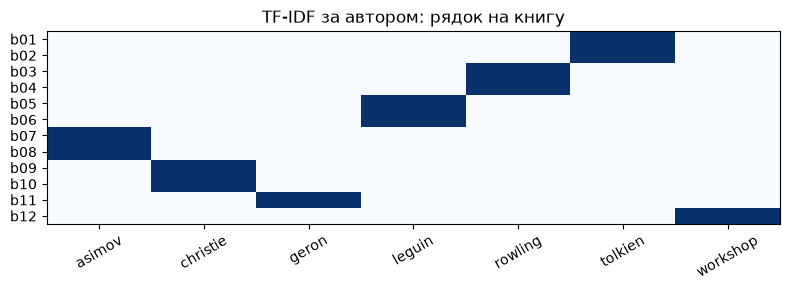

In [11]:
fig, ax = plt.subplots(figsize=(8,3))
ax.imshow(author_X.toarray(),cmap='Blues',vmin=0,vmax=1,aspect='auto')
ax.set(xticks=range(author_X.shape[1]),xticklabels=author_vectorizer.get_feature_names_out(),
       yticks=range(len(books)),yticklabels=books.book_id,title='TF-IDF за автором: рядок на книгу')
ax.tick_params(axis='x',rotation=30)
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 3. Змініть текстове поле.** Побудуйте окремий TF-IDF на authors + пробіл + title. Надрукуйте кількість колонок до й після зміни. Поясніть, чому додавання назви змінює поняття схожості.

### Підказки

1. Початкову модель авторів збережіть без змін.
2. Тексти: `books['authors'] + ' ' + books['title']`.
3. Створіть новий TfidfVectorizer і викличте fit_transform.
4. shape[1] — число ознак, а не книжок.
5. Назви українською токенізуються, але без лематизації споріднені форми слів можуть лишитися різними ознаками.

**Готово, якщо:** Є дві матриці та пояснення, які саме слова тепер впливають на результат.

In [ ]:
# Завдання 3: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 4. 35.2 · Cosine: вимірюємо спільний напрямок

**65–90 хв.**

## Чому спільні слова дають схожість

**Факт 4. Cosine порівнює напрямки ненульових векторів, а не кількість покупок чи якість книжки.**

Схема: два TF-IDF-вектори → скалярний добуток / добуток довжин → оцінка близькості.

Для двох векторів a і b формула: sum(a*b)/(norm(a)*norm(b)). Наприклад [1,0] та [2,0] мають однаковий напрямок, cosine=1, хоча друга довжина більша. [1,0] і [0,1] не мають спільного напрямку, cosine=0.

Для невід'ємних TF-IDF-ознак близькість від 0 до 1. Загалом cosine для довільних дійсних векторів може бути від -1 до 1. Оцінка 0.8 не означає 80% імовірності, що книга сподобається: це близькість у нашому представленні.

Матриця cosine авторів має форму 12×12: рядок — запитана книга, колонка — кандидат. Діагональ для ненульового рядка дорівнює 1: книга найбільше схожа сама на себе. Під час рекомендації її потрібно явно прибрати. Нульовий вектор математично не має визначеного кута; sklearn повертає для нього нульові подібності — такий результат потребує пояснення, а не вигаданого рейтингу.

У великому каталозі не обов'язково зберігати повну квадратну матрицю. Можна порівнювати один запит зі всіма або шукати лише найближчих кандидатів. Сьогодні квадратна матриця маленька й корисна для наочності.

In [13]:
author_vectorizer = TfidfVectorizer()
author_X = author_vectorizer.fit_transform(books.authors)

### Приклад: основний код

In [14]:
author_sim = cosine_similarity(author_X)
print(pd.DataFrame(author_sim,index=books.book_id,columns=books.book_id).round(2))

book_id  b01  b02  b03  b04  b05  b06  b07  b08  b09  b10  b11  b12
book_id                                                            
b01      1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
b02      1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
b03      0.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
b04      0.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
b05      0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0
b06      0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  0.0
b07      0.0  0.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0
b08      0.0  0.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0
b09      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0
b10      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0
b11      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0
b12      0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  1.0


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

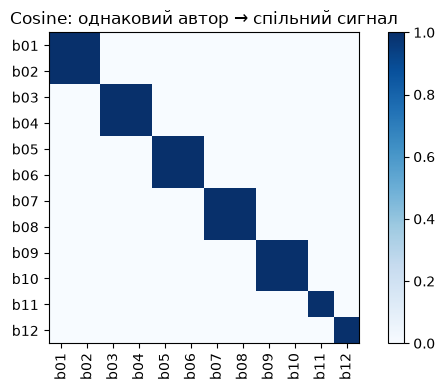

In [15]:
fig, ax = plt.subplots(figsize=(6,4))
picture = ax.imshow(author_sim,vmin=0,vmax=1,cmap='Blues')
ax.set(xticks=range(len(books)),xticklabels=books.book_id,
       yticks=range(len(books)),yticklabels=books.book_id,title='Cosine: однаковий автор → спільний сигнал')
ax.tick_params(axis='x',rotation=90)
fig.colorbar(picture,ax=ax)
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 4. Порахуйте cosine руками й кодом.** Для a=[1,1,0], b=[1,0,1] знайдіть добуток, довжини та cosine. Звірте зі sklearn. Потім виведіть близькість b01 до b02 і b03 за автором та поясніть різницю.

### Підказки

1. Перетворіть списки на np.array з float.
2. Чисельник: np.dot(a,b); довжина: np.linalg.norm(a).
3. Для перевірки sklearn очікує двовимірні масиви: `cosine_similarity([a],[b])[0,0]`.
4. Побудуйте author_sim, якщо запускаєте завдання окремо.
5. Індекси рядків для b01,b02,b03 у навчальному каталозі — 0,1,2; у загальному коді шукайте ID явно.

**Готово, якщо:** Є ручний розрахунок 0.5 та пояснення, чому спільний автор дає інший результат, ніж різний.

In [ ]:
# Завдання 4: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 5. 35.3 · Рекомендація: ID, self-hit і чесний top-n

**90–115 хв.**

## Перетворюємо близькість на список

**Факт 5. Рекомендація потребує правил відбору: знайти ID, прибрати саму книгу й упорядкувати кандидатів.**

Схема: book_id → рядок схожості → без self і нульового сигналу → стабільне сортування → top-n.

Для b01 очікуємо іншу книгу Tolkien, а не повторення Гобіта. Якщо просто взяти найбільші числа, першою вийде сама b01. Тому self-hit прибираємо через ID, а не сліпо зрізом першого елемента: за однакових оцінок порядок може бути іншим.

Кількість n — верхня межа, а не обіцянка. За одного схожого автора список може містити лише одну книгу. Нульові оцінки не дають доказу схожості; повертати їх як «найкращі рекомендації» було б оманливо. Для однакових score застосуємо другий ключ book_id, щоб результат був відтворюваним.

Невідомий ID — помилка запиту; невідомий або порожній текст — відсутність сигналу. Ці ситуації слід розрізняти. Готова функція не повинна випадково брати чужий рядок, коли потрібної книги немає.

In [17]:
author_vectorizer = TfidfVectorizer()
author_X = author_vectorizer.fit_transform(books.authors)
author_sim = cosine_similarity(author_X)

### Приклад: основний код

In [18]:
seed_id = 'b01'
seed_position = books.index[books.book_id == seed_id][0]
candidates = books[['book_id','title']].copy()
candidates['score'] = author_sim[seed_position]
candidates = candidates.loc[(candidates.book_id != seed_id) & (candidates.score > 0)]
print(candidates.sort_values(['score','book_id'],ascending=[False,True]).head(3).to_string(index=False))

book_id           title  score
    b02 Володар перснів    1.0


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

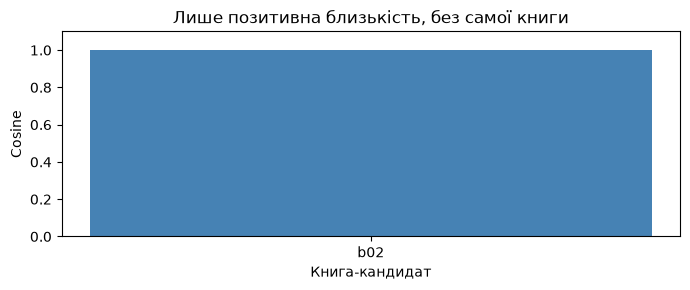

In [19]:
fig, ax = plt.subplots(figsize=(7,3))
shown = candidates.sort_values(['score','book_id'],ascending=[False,True]).head(3)
ax.bar(shown.book_id,shown.score,color='steelblue')
ax.set(ylim=(0,1.1),xlabel='Книга-кандидат',ylabel='Cosine',title='Лише позитивна близькість, без самої книги')
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 5. Напишіть recommend_book(book_id, n=3).** Поверніть DataFrame з book_id, title і score, без самої книги та нульової близькості. Невідомий ID має давати зрозумілий ValueError, n<=0 — також. Перевірте b03 і невідомий b99.

### Підказки

1. Знайдіть позиції за `books.index[books.book_id == book_id]` і перевірте len.
2. Демо вже показує фільтр, потрібні лише параметри функції та перевірки.
3. Відсортуйте score за спаданням, book_id за зростанням.
4. Візьміть head(n), не доповнюйте нулями короткий результат.
5. Викличте функцію в try/except ValueError для b99 і надрукуйте повідомлення.

**Готово, якщо:** Є функція, перевірка self-hit та зрозумілий результат невідомого ID.

In [ ]:
# Завдання 5: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 6. 35.4 · Новий читач: опис інтересу та нульовий вектор

**115–140 хв.**

## Порадити можна й без історії оцінок

**Факт 6. Текст інтересу можна порівняти з описами книг через той самий навчений словник.**

Схема: описи → fit TF-IDF; інтерес читача → transform → cosine до описів → без уже прочитаного.

Новий читач написав «python machine learning». Авторський вектор тут не допомагає: у запиті немає Tolkien чи Geron. Для цієї окремої моделі використаємо description. Англійські ключові слова в локальних описах написані спеціально для вправи, щоб не додавати морфологічний аналіз української.

Для запиту не викликаємо новий fit: словник і ваги мають залишитися сумісними з векторами каталогу. Запит transform дає один рядок із тими самими колонками. cosine_similarity(query,description_X) повертає 1×12 оцінок.

Якщо всі слова невідомі словнику, query.nnz дорівнює 0. Повертати top із нулів не варто: немає сигналу. У такому разі можна попросити уточнити інтерес або явно запропонувати неперсональний список. Також прибираємо вже прочитані книги: цей фільтр потрібен незалежно від методу.

Content-based не розуміє синоніми автоматично: «coding» та «python» не стануть близькими без спільних токенів чи додаткового представлення. Новий текст або книга поза словником потребують перевірки, а при оновленні словника треба перерахувати всі вектори каталогу.

In [21]:
description_vectorizer = TfidfVectorizer()
description_X = description_vectorizer.fit_transform(books.description)

### Приклад: основний код

In [22]:
query = description_vectorizer.transform(['python machine learning'])
scores = cosine_similarity(query,description_X)[0]
ranking = books[['book_id','title']].assign(score=scores)
print(ranking.loc[ranking.score > 0].sort_values(['score','book_id'],ascending=[False,True]).head(3).to_string(index=False))
print('Невідомі слова, ненульових координат:',description_vectorizer.transform(['quokka']).nnz)

book_id                       title    score
    b11  Прикладне машинне навчання 0.829899
    b12 Навчальний довідник моделей 0.829899
Невідомі слова, ненульових координат: 0


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

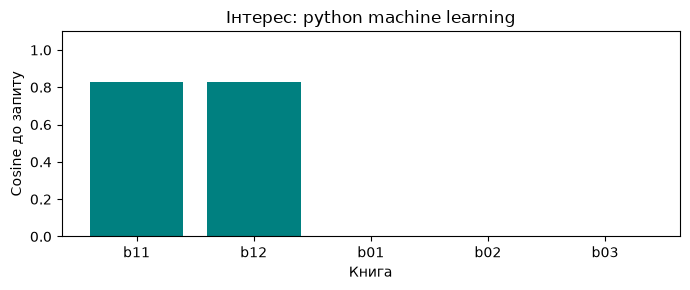

In [23]:
fig, ax = plt.subplots(figsize=(7,3))
shown = ranking.sort_values(['score','book_id'],ascending=[False,True]).head(5)
ax.bar(shown.book_id,shown.score,color='teal')
ax.set(ylim=(0,1.1),xlabel='Книга',ylabel='Cosine до запиту',title='Інтерес: python machine learning')
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 6. Персональний фільтр і порожній сигнал.** Для запиту «fantasy magic school» поверніть до трьох книг, прибравши прочитану b03. Потім обробіть «quokka»: замість довільних кандидатів надрукуйте прохання уточнити інтерес.

### Підказки

1. Використайте description_vectorizer.transform та description_X із контексту.
2. Перед cosine перевірте query.nnz; якщо нуль, повідомте про відсутність знайомих слів.
3. До фільтра score>0 додайте `~result.book_id.isin({'b03'})`.
4. Відомі слова не гарантують ідеальної поради: поясніть, які саме токени підняли кандидата.

**Готово, якщо:** Немає прочитаної b03; невідомий запит не породжує фальшиву рекомендацію.

In [ ]:
# Завдання 6: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 7. 36.1 · Оцінки читачів: пропуск не є нуль зірок

**140–165 хв.**

## Інший сигнал для тієї самої книгарні

**Факт 7. У матриці явних рейтингів порожня клітинка означає невідому оцінку, а не погану книгу.**

Схема: user_id, book_id, rating → pivot → читачі × книги → маска відомих оцінок.

У локальній таблиці є оцінки 1..5 та час події. Для уроку вже відокремлено історію train до 1 лютого 2026 та майбутні test-події після цього моменту. Уся побудова сусідів і рекомендацій працює тільки з train. Майбутні оцінки побачимо лише наприкінці для перевірки.

Довгий формат зручний для збереження: один рядок — оцінка однієї книги одним читачем. Pivot робить матрицю, де рядки — читачі, колонки — book_id. На місці невідомого зберігаємо NaN. Повторні оцінки однієї пари потрібно обробити за явним правилом: наприклад, брати останню за часом; наші дані повторів не мають, а функція перевіряє це.

Для простого cosine користувачів створимо технічну копію fillna(0). Оригінальна матриця лишається з NaN, щоб відрізняти невідоме від реальної низької оцінки. Ця навчальна схожість не центрує рейтинги та чутлива до повноти історії й щедрості читача; це спрощений baseline, а не універсальна модель смаку.

Покупка, перегляд і оцінка — різні типи сигналів. Відсутність покупки теж не доводить нелюбов; не змішуйте implicit-події зі шкалою явних зірок без окремого пояснення.

### Приклад: основний код

In [25]:
def rating_matrix(table):
    """NaN зберігається в матриці явних оцінок."""
    if table.duplicated(['user_id','book_id']).any():
        raise ValueError('Спочатку узгодьте політику повторних оцінок')
    return table.pivot(index='user_id',columns='book_id',values='rating')

def user_similarities(matrix):
    """Нуль — лише технічне заповнення для cosine; оригінальні NaN збережені."""
    return pd.DataFrame(cosine_similarity(matrix.fillna(0)),
                        index=matrix.index, columns=matrix.index)

matrix = rating_matrix(train)
similarities = user_similarities(matrix)
print(matrix.to_string())
print('Відомих оцінок:',int(matrix.notna().sum().sum()))
print('Схожість на Olia:',similarities.loc['Olia'].round(3).to_dict())

book_id  b01  b02  b03  b04  b05  b06  b07  b08  b09  b10
user_id                                                  
Ira      5.0  5.0  4.0  4.0  NaN  3.0  NaN  NaN  1.0  NaN
Lena     5.0  NaN  4.0  4.0  3.0  NaN  NaN  NaN  1.0  NaN
Max      1.0  NaN  1.0  NaN  NaN  NaN  5.0  5.0  4.0  5.0
Nadia    2.0  2.0  2.0  NaN  5.0  5.0  NaN  NaN  3.0  NaN
Olia     5.0  NaN  4.0  NaN  4.0  NaN  NaN  NaN  1.0  NaN
Taras    4.0  4.0  5.0  5.0  4.0  NaN  NaN  NaN  2.0  NaN
Відомих оцінок: 33
Схожість на Olia: {'Ira': 0.575, 'Lena': 0.866, 'Max': 0.177, 'Nadia': 0.639, 'Olia': 1.0, 'Taras': 0.754}


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

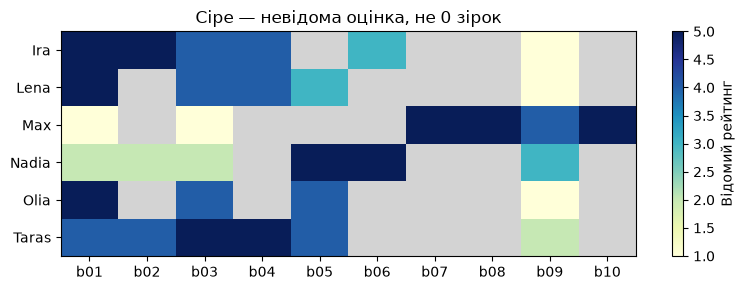

In [26]:
fig, ax = plt.subplots(figsize=(8,3))
cmap = plt.get_cmap('YlGnBu').copy()
cmap.set_bad('lightgray')
image = ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),vmin=1,vmax=5,cmap=cmap,aspect='auto')
ax.set(xticks=range(len(matrix.columns)),xticklabels=matrix.columns,
       yticks=range(len(matrix.index)),yticklabels=matrix.index,title='Сіре — невідома оцінка, не 0 зірок')
fig.colorbar(image,ax=ax,label='Відомий рейтинг')
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 7. Виміряйте порожнечі.** Порахуйте кількість відомих і невідомих клітинок, частку заповнення. Виведіть книги, які Оля вже оцінила, і книги каталогу, яких вона ще не оцінила. Перевірте, що b02 у її історії train відсутня.

### Підказки

1. matrix = rating_matrix(train); notna().sum().sum() рахує відомі.
2. matrix.size — загальне число клітинок у pivot, а не число подій.
3. Для Олі використайте `train.loc[train.user_id == 'Olia','book_id']`.
4. Кандидати — set(books.book_id) мінус seen; це включає також книги без жодних оцінок.
5. Не підміняйте train повною events: b02 для Олі є майбутньою перевіркою.

**Готово, якщо:** Підрахунок узгоджений із train, невідомі оцінки не стали нульовими цілями.

In [ ]:
# Завдання 7: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 8. 36.2 · Прогноз рейтингу: хто саме має право голосу

**165–190 хв.**

## Голосують лише сусіди, які оцінили кандидата

**Факт 8. Зважений прогноз ділиться на суму ваг тільки тих інших читачів, чиї оцінки кандидата відомі.**

Схема: кандидат → відомі рейтинги інших → ваги схожості → sum(w*r)/sum(w).

Нехай Іра має вагу 0.8 й поставила 5, Тарас має 0.2 й поставив 3, а третій читач із вагою 0.9 книгу не оцінив. Прогноз: (0.8×5+0.2×3)/(0.8+0.2)=4.6. Третій не входить ні в чисельник, ні в знаменник. Інакше невідоме непомітно перетвориться на негативний голос.

Самого користувача прибираємо зі списку сусідів. За нашими позитивними шкалами cosine невід'ємний, тому беремо лише ваги >0. Якщо жодного голосу немає або сума ваг нульова, повернемо None — прогнозу немає. Не видаємо його за 0 зірок і не ділимо на нуль.

Це простий user-based baseline: середнє рейтингів сусідів без центрування. Люди можуть по-різному користуватися шкалою; зважений результат не є відкаліброваною впевненістю. Якщо ваги додатні, прогноз лежить між мінімальною та максимальною оцінками використаних сусідів.

In [28]:
def rating_matrix(table):
    """NaN зберігається в матриці явних оцінок."""
    if table.duplicated(['user_id','book_id']).any():
        raise ValueError('Спочатку узгодьте політику повторних оцінок')
    return table.pivot(index='user_id',columns='book_id',values='rating')

def user_similarities(matrix):
    """Нуль — лише технічне заповнення для cosine; оригінальні NaN збережені."""
    return pd.DataFrame(cosine_similarity(matrix.fillna(0)),
                        index=matrix.index, columns=matrix.index)

matrix = rating_matrix(train)
similarities = user_similarities(matrix)

### Приклад: основний код

In [29]:
def predict_rating(matrix, similarities, user, book):
    """Середнє оцінок тільки тих інших користувачів, хто оцінив цю книжку."""
    if user not in matrix.index or book not in matrix.columns:
        return None
    known = matrix[book].dropna().drop(index=user, errors='ignore')
    weights = similarities.loc[user].reindex(known.index)
    positive = weights > 0
    known, weights = known[positive], weights[positive]
    if weights.sum() <= 0:
        return None
    return float(np.dot(weights.to_numpy(), known.to_numpy()) / weights.sum())

print('Прогноз Olia/b02:',predict_rating(matrix,similarities,'Olia','b02'))
print('Книга без оцінок b12:',predict_rating(matrix,similarities,'Olia','b12'))

Прогноз Olia/b02: 3.6428477044325462
Книга без оцінок b12: None


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

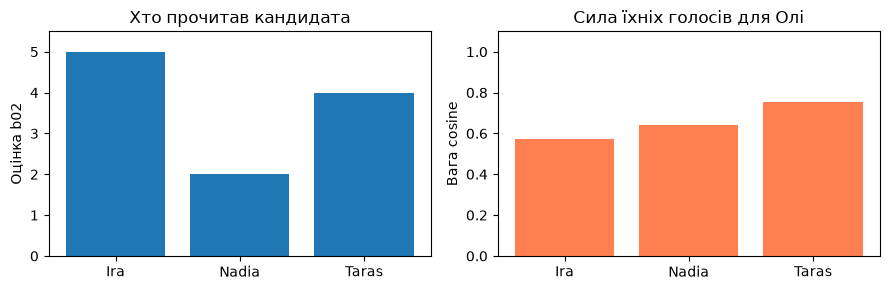

In [30]:
known_votes = matrix['b02'].dropna().drop(index='Olia',errors='ignore')
vote_weights = similarities.loc['Olia'].reindex(known_votes.index)
fig, axes = plt.subplots(1,2,figsize=(9,3))
axes[0].bar(known_votes.index,known_votes.values)
axes[0].set(ylabel='Оцінка b02',ylim=(0,5.5),title='Хто прочитав кандидата')
axes[1].bar(vote_weights.index,vote_weights.values,color='coral')
axes[1].set(ylabel='Вага cosine',ylim=(0,1.1),title='Сила їхніх голосів для Олі')
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 8. Перевірте знаменник самостійно.** Для кандидата b06 зберіть рейтинги інших читачів, що оцінили його, і їхні ваги схожості з Олею. Порахуйте прогноз через dot та суму ваг. Порівняйте з predict_rating. Надрукуйте також суму ваг усіх інших читачів і поясніть, чому її не можна брати знаменником.

### Підказки

1. `matrix['b06'].dropna()` лишає тільки відомі оцінки; приберіть Olia через drop(errors='ignore').
2. `similarities.loc['Olia'].reindex(rated.index)` вирівнює ваги й оцінки за іменами, а не випадковим порядком.
3. Залиште positive = weights > 0 в обох об'єктах.
4. Перевірте weights.sum() перед діленням.
5. Відомий прогноз — np.dot(weights, rated)/weights.sum(); порівняння через np.isclose.

**Готово, якщо:** Прогноз використовує тільки наявні оцінки кандидата та вирівняні ваги.

In [ ]:
# Завдання 8: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 9. 36.3 · Список для читача: unseen, cold start і CSV

**190–215 хв.**

## Прогноз ще треба перетворити на рекомендацію

**Факт 9. Хороший список виключає вже оцінене й чесно позначає fallback, коли персонального сигналу немає.**

Схема: історія читача → unseen → прогноз для кандидатів → сортування → CSV; немає історії → популярність.

Із каталогу прибираємо книги, вже оцінені цим читачем у train. Для решти обчислюємо прогноз, пропускаємо None, сортуємо й беремо top-n. Невідомий користувач не має рядка схожості: це cold start. Йому можна запропонувати популярність або попросити інтерес і використати content-based із пари 35.

Наш fallback спочатку сортує за кількістю оцінок, потім за середньою оцінкою та ID. Це прозоре неперсональне правило, не «штучний смак» нового користувача. Воно має popularity bias: маловідомі книги майже не отримують шансів. Поле reason у результаті показує, яке правило спрацювало.

Можливий ще один cold start: нова книга без жодного рейтингу. Collaborative не має для неї оцінок, але content-based може використати її опис. Якщо отримали менше n кандидатів, повертаємо коротший список, не домішуючи довільні нулі.

Результат практикуму — book_recommendations.csv, а не лише красивий print. UTF-8 із BOM зручно відкривається в багатьох табличних редакторах. Перед записом створимо папку results; шлях будуємо від пакета, щоб запуск з іншого каталогу не загубив файл.

In [32]:
def rating_matrix(table):
    """NaN зберігається в матриці явних оцінок."""
    if table.duplicated(['user_id','book_id']).any():
        raise ValueError('Спочатку узгодьте політику повторних оцінок')
    return table.pivot(index='user_id',columns='book_id',values='rating')

def user_similarities(matrix):
    """Нуль — лише технічне заповнення для cosine; оригінальні NaN збережені."""
    return pd.DataFrame(cosine_similarity(matrix.fillna(0)),
                        index=matrix.index, columns=matrix.index)

def predict_rating(matrix, similarities, user, book):
    """Середнє оцінок тільки тих інших користувачів, хто оцінив цю книжку."""
    if user not in matrix.index or book not in matrix.columns:
        return None
    known = matrix[book].dropna().drop(index=user, errors='ignore')
    weights = similarities.loc[user].reindex(known.index)
    positive = weights > 0
    known, weights = known[positive], weights[positive]
    if weights.sum() <= 0:
        return None
    return float(np.dot(weights.to_numpy(), known.to_numpy()) / weights.sum())

### Приклад: основний код

In [33]:
def popularity(table, catalog, seen=(), n=3):
    """Fallback: спочатку кількість оцінок, потім середній рейтинг та стабільний ID."""
    stats = table.groupby('book_id').rating.agg(['count','mean']).reset_index()
    stats = stats.loc[~stats.book_id.isin(set(seen))]
    stats = stats.sort_values(['count','mean','book_id'],ascending=[False,False,True])
    return stats.head(n).merge(catalog[['book_id','title']],on='book_id',how='left')

def recommend_user(table, catalog, user, n=3):
    """Приклад складання списку; жодних невідомих оцінок у знаменнику."""
    matrix = rating_matrix(table)
    if user not in matrix.index:
        result = popularity(table,catalog,n=n)
        return result.assign(reason='популярність: немає історії')
    similarities = user_similarities(matrix)
    seen = set(table.loc[table.user_id == user,'book_id'])
    candidates = []
    for book in catalog.book_id:
        if book in seen:
            continue
        score = predict_rating(matrix,similarities,user,book)
        if score is not None:
            candidates.append((book,score))
    if not candidates:
        return popularity(table,catalog,seen,n).assign(reason='популярність: немає сигналу')
    result = pd.DataFrame(candidates,columns=['book_id','score'])
    result = result.sort_values(['score','book_id'],ascending=[False,True]).head(n)
    return result.merge(catalog[['book_id','title']],on='book_id').assign(reason='оцінки сусідів')

print('Для Olia:')
print(recommend_user(train,books,'Olia',n=3).round(3).to_string(index=False))
print('Для нового читача:')
print(recommend_user(train,books,'NewReader',n=3).to_string(index=False))

Для Olia:
book_id  score          title         reason
    b07    5.0       Фундація оцінки сусідів
    b08    5.0       Я, робот оцінки сусідів
    b10    5.0 Смерть на Нілі оцінки сусідів
Для нового читача:
book_id  count     mean                              title                      reason
    b01      6 3.666667                              Гобіт популярність: немає історії
    b03      6 3.333333 Гаррі Поттер і філософський камінь популярність: немає історії
    b09      6 2.000000       Убивство у Східному експресі популярність: немає історії


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

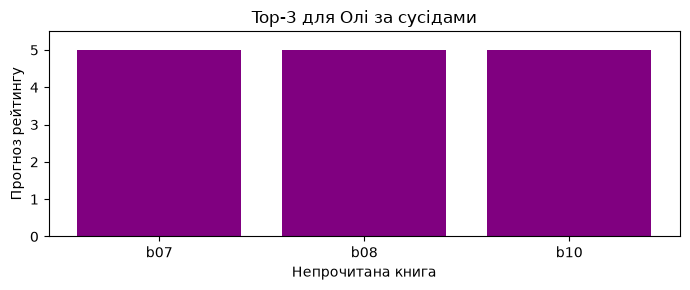

In [34]:
shown = recommend_user(train,books,'Olia',n=3)
fig, ax = plt.subplots(figsize=(7,3))
ax.bar(shown.book_id,shown.score,color='purple')
ax.set(ylabel='Прогноз рейтингу',ylim=(0,5.5),xlabel='Непрочитана книга',title='Top-3 для Олі за сусідами')
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 9. Збережіть результат.** Отримайте top-3 для Olia, перевірте відсутність уже оцінених книг, запишіть у results/book_recommendations.csv. Прочитайте файл назад і звірте список ID. Окремо викличте рекомендацію для NewReader та поясніть reason.

### Підказки

1. recommend_user уже розібрано в демонстрації; використайте його без нових формул.
2. seen визначайте за train, а не events.
3. Перетин set(result.book_id) & seen має бути порожнім.
4. OUTPUT_DIR.mkdir(parents=True,exist_ok=True); шлях OUTPUT_DIR/'book_recommendations.csv'.
5. to_csv(index=False,encoding='utf-8-sig'), потім pd.read_csv з тим самим кодуванням.

**Готово, якщо:** CSV існує, ID після читання збігаються, self-history відсутня, fallback підписано.

In [ ]:
# Завдання 9: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.


# Блок 10. 36.4 · Перевірка без майбутнього та завершений звіт

**215–240 хв.**

## Чи справді список корисний

**Факт 10. Якість перевіряють на майбутніх подіях, яких не було ані в сусідах, ані в статистиках популярності.**

Схема: спільний cutoff → train для всіх перетворень → майбутні test → покриття й MAE → обережний висновок.

Часовий поділ у цьому пакеті зроблено до рекомендацій. Окреме «останнє читання кожної людини» без загального часу може залишити майбутні оцінки інших людей у train. Тому тут усі train-події передують усім test-подіям.

MAE — середня абсолютна помилка прогнозованих зірок. Для 5 зірок і прогнозу 4.5 помилка 0.5. Якщо модель не змогла дати прогноз, повідомляємо покриття — частку тестових подій із прогнозом. Не підміняємо відсутні прогнози нулями та не приховуємо пропущені випадки.

Порівняємо з простим baseline: середній рейтинг кожної книги за train. Обидві MAE рахуємо на тих самих тестових подіях, де доступні обидва прогнози. Шість штучних тестових оцінок — лише демонстрація протоколу, а не доказ переваги методу.

Малий MAE не гарантує доброго top-3: список може повторювати прочитане, бути одноманітним чи показувати лише хіти. Окремо перевіряйте ранжування, новизну, різноманітність і продуктову користь. Якщо частина смаків не представлена, потрібні нові сигнали, а не лише ще одна формула.

Сьогодні ми використовували memory-based сусідів. Surprise.SVD або навчання таблиць embedding — інший, model-based шлях, він не є тим самим матричним SVD із пари 31. Ці розширення не потрібні для проходження й не додають прихованих залежностей.

In [36]:
def rating_matrix(table):
    """NaN зберігається в матриці явних оцінок."""
    if table.duplicated(['user_id','book_id']).any():
        raise ValueError('Спочатку узгодьте політику повторних оцінок')
    return table.pivot(index='user_id',columns='book_id',values='rating')

def user_similarities(matrix):
    """Нуль — лише технічне заповнення для cosine; оригінальні NaN збережені."""
    return pd.DataFrame(cosine_similarity(matrix.fillna(0)),
                        index=matrix.index, columns=matrix.index)

def predict_rating(matrix, similarities, user, book):
    """Середнє оцінок тільки тих інших користувачів, хто оцінив цю книжку."""
    if user not in matrix.index or book not in matrix.columns:
        return None
    known = matrix[book].dropna().drop(index=user, errors='ignore')
    weights = similarities.loc[user].reindex(known.index)
    positive = weights > 0
    known, weights = known[positive], weights[positive]
    if weights.sum() <= 0:
        return None
    return float(np.dot(weights.to_numpy(), known.to_numpy()) / weights.sum())

### Приклад: основний код

In [37]:
print('Train:',len(train),'Test:',len(test))
print('Останній train:',train.timestamp.max(),'Перший test:',test.timestamp.min())
print('Тестові події:')
print(test[['user_id','book_id','rating','timestamp']].to_string(index=False))
assert train.timestamp.max() < test.timestamp.min()

Train: 33 Test: 6
Останній train: 2026-01-25 00:00:00 Перший test: 2026-03-01 00:00:00
Тестові події:
user_id book_id  rating  timestamp
   Olia     b02       5 2026-03-01
    Ira     b05       4 2026-03-02
    Max     b02       1 2026-03-03
  Taras     b06       4 2026-03-04
  Nadia     b04       2 2026-03-05
   Lena     b02       5 2026-03-06


### Графічне пояснення прикладу · окремий Matplotlib-блок

Виконуйте після основного коду; блок не змінює модель.

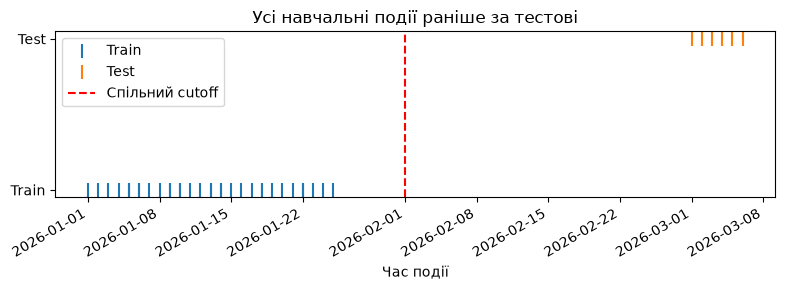

In [38]:
fig, ax = plt.subplots(figsize=(8,3))
ax.scatter(train.timestamp,np.zeros(len(train)),label='Train',marker='|',s=100)
ax.scatter(test.timestamp,np.ones(len(test)),label='Test',marker='|',s=100)
ax.axvline(cutoff,color='red',linestyle='--',label='Спільний cutoff')
ax.set(yticks=[0,1],yticklabels=['Train','Test'],xlabel='Час події',title='Усі навчальні події раніше за тестові')
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### Спробуйте самостійно

**Завдання 10. Порівняйте з baseline.** Для кожного рядка test отримайте прогноз із матриці, побудованої тільки на train, та середній рейтинг книги за train. На спільно покритих рядках обчисліть обидві MAE. Повідомте покриття й напишіть чотири речення: який сигнал у кожного методу, що робити з новим читачем, чому MAE замало, що перевіряти на реальних даних.

### Підказки

1. Побудуйте matrix і similarities заново саме з train.
2. Середні baseline: `train.groupby('book_id').rating.mean()`.
3. Перебирайте test.itertuples(index=False), використовуйте row.user_id, row.book_id, row.rating.
4. Якщо predict_rating дав None або середнього для книги немає, не включайте рядок в обидві MAE.
5. Для спільного DataFrame: abs(prediction-rating).mean(); покриття = число цих рядків / len(test).
6. Якщо спільних рядків немає, явно повідомте про неможливість порівняння.

**Готово, якщо:** Є часовий поділ, покриття та обидві MAE на тих самих рядках; висновок не перебільшує результат.

In [ ]:
# Завдання 10: напишіть власний код за умовою та підказками.
# Початкові змінні з контексту вже доступні.



## Що маєте після заняття

Два способи рекомендацій, пояснення їхніх обмежень, CSV зі списком для читача та перевірку без майбутніх оцінок. Пригадайте різницю: кластери описують схожі об'єкти; content-based порівнює ознаки книг; collaborative використовує спільні реакції читачів.

**Де перечитати:** місток — блоки 1–2; текстові рекомендації — 3–6; рейтинги, fallback і перевірка — 7–10. Відповідний код є в examples/example_01.py … example_10.py; ваші самостійні спроби — у tasks/task_01.py … task_10.py.

## Необов'язкове продовження

Додайте нову книгу з описом, але без рейтингів. Порівняйте, який метод здатний її запропонувати. Потім придумайте, як показувати причину рекомендації та зменшити одноманітність top-n. Ця робота не входить до 240 хв.
